In [1]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

API_KEY = getpass("Enter your IBM Quantum API key: ")
CRN = input("Enter your CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=API_KEY,
    instance=CRN
)

backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=2
)

print("Connected successfully!")
print("Quantum computer:", backend.name)

Enter your IBM Quantum API key:  ········
Enter your CRN:  crn:v1:bluemix:public:quantum-computing:us-east:a/9c3e1070343e4b4cb8347c890455459c:ff3ebefb-8e76-4cf2-b5fb-4f8ae917c63c::


qiskit_runtime_service._discover_account:WARNING:2026-10-11 18:41:12,501: Loading account with the given token. A saved account will not be used.


Connected successfully!
Quantum computer: ibm_fez


PART A: CORRELATED OUTCOMES


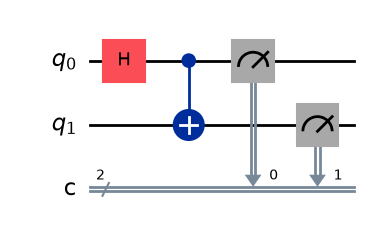

PART B: OPPOSITE OUTCOMES


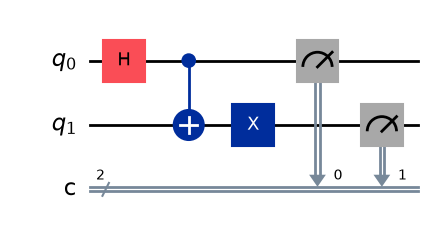

In [2]:
from qiskit import QuantumCircuit

# Part A: Correlated outcomes
circuit_A = QuantumCircuit(2, 2)

circuit_A.h(0)
circuit_A.cx(0, 1)

circuit_A.measure([0, 1], [0, 1])


# Part B: Opposite outcomes
circuit_B = QuantumCircuit(2, 2)

circuit_B.h(0)
circuit_B.cx(0, 1)
circuit_B.x(1)

circuit_B.measure([0, 1], [0, 1])


print("PART A: CORRELATED OUTCOMES")
display(circuit_A.draw("mpl"))

print("PART B: OPPOSITE OUTCOMES")
display(circuit_B.draw("mpl"))

In [3]:
print("PART A PREDICTION")
print("Dominant outcomes: 00 and 11")
print("Expected probability: 50% each")

print("\nPART B PREDICTION")
print("Dominant outcomes: 01 and 10")
print("Expected probability: 50% each")

PART A PREDICTION
Dominant outcomes: 00 and 11
Expected probability: 50% each

PART B PREDICTION
Dominant outcomes: 01 and 10
Expected probability: 50% each


In [ ]:
from qiskit import transpile
from qiskit_ibm_runtime import SamplerV2 as Sampler

circuits = [circuit_A, circuit_B]

compiled_circuits = transpile(
    circuits,
    backend=backend
)

sampler = Sampler(mode=backend)

job = sampler.run(
    compiled_circuits,
    shots=100
)

print("Job ID:", job.job_id())

results = job.result()

counts_A = results[0].data.c.get_counts()
counts_B = results[1].data.c.get_counts()

print("\nPART A RESULTS:", counts_A)
print("PART B RESULTS:", counts_B)

C:\Users\prane\AppData\Local\Temp\ipykernel_25620\2491631248.py:11: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Job ID: db5omao4qg6s73c3phgg
